# Tumor Segmentation in MRI Volumes

### Loading Data

In [1]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("/l/users/faiz.ramadhan/brain_tumor/Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
split_df = pd.read_csv(SPLIT_FILE)

assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}

for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


## Inspect Data

In [2]:
from pathlib import Path
import nibabel as nib
import numpy as np

images_dir = DATA_ROOT / "imagesTr"
labels_dir = DATA_ROOT / "labelsTr"

# Get image cases
image_files = sorted(
    p for p in images_dir.glob("*.nii.gz")
    if not p.name.startswith("._")
)

# Load at least 3 cases
for image_path in image_files[:3]:
    case_id = image_path.name.replace(".nii.gz", "")
    label_path = labels_dir / f"{case_id}.nii.gz"

    image_nii = nib.load(image_path)
    label_nii = nib.load(label_path)

    image = image_nii.get_fdata()
    label = label_nii.get_fdata()

    print("=" * 80)
    print(f"CASE: {case_id}")
    print(f"Image shape: {image.shape}")
    print(f"Label shape: {label.shape}")

    print("\nAffine:")
    print(image_nii.affine)

    print("\nOrientation:")
    print(nib.aff2axcodes(image_nii.affine))

    print("\nVoxel spacing:")
    print(image_nii.header.get_zooms()[:3])

    print("\nLabel values:")
    print(np.unique(label))

CASE: BRATS_001
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]
CASE: BRATS_002
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]
CASE: BRATS_003
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)

Affine:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Orientation:
('R', 'A', 'S')

Voxel spacing:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Label values:
[0. 1. 2. 3.]


Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Selected voxel: (np.int64(157), np.int64(116), np.int64(67))
Selected slice: 67
4


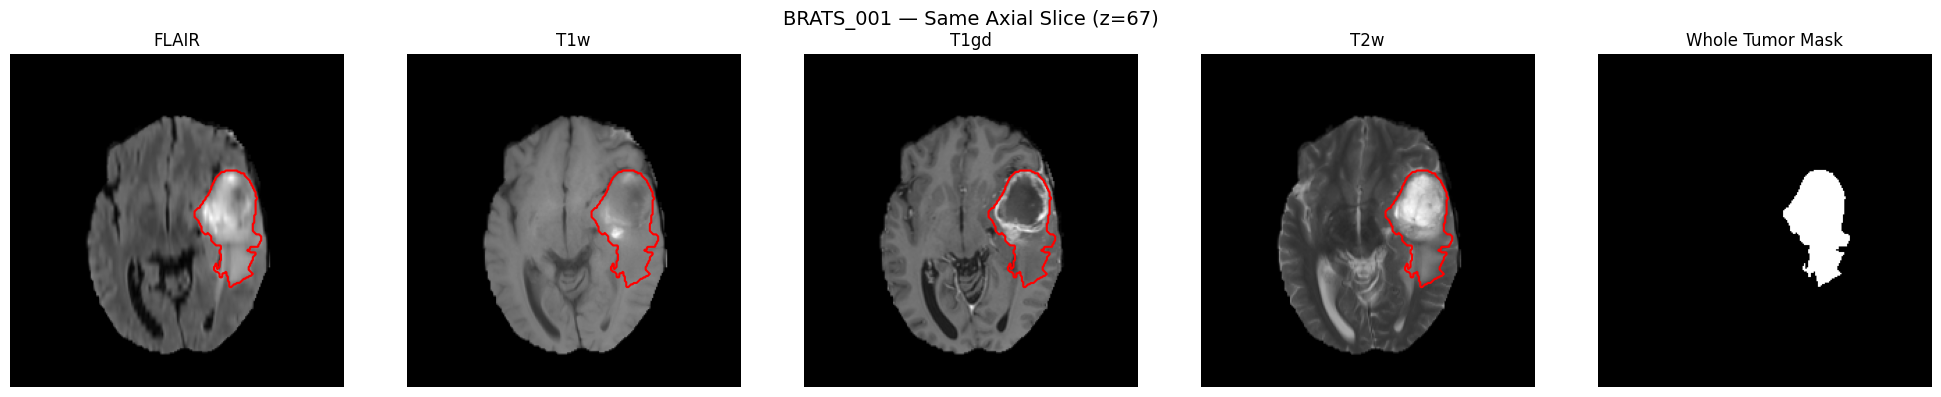

In [3]:
import matplotlib.pyplot as plt

case = "BRATS_001"

image_path = DATA_ROOT / "imagesTr" / f"{case}.nii.gz"
label_path = DATA_ROOT / "labelsTr" / f"{case}.nii.gz"

image_nii = nib.load(image_path)
label_nii = nib.load(label_path)

image = image_nii.get_fdata()
label = label_nii.get_fdata()

print("Image shape:", image.shape)
print("Label shape:", label.shape)


# Channel order from dataset.json
modalities = {
    "FLAIR": image[..., 0],
    "T1w":   image[..., 1],
    "T1gd":  image[..., 2],
    "T2w":   image[..., 3],
}


# Tumor mask
# 0 = background
# 1 = edema
# 2 = non-enhancing tumor
# 3 = enhancing tumor
#
# Whole tumor = labels 1 + 2 + 3

whole_tumor = (label > 0).astype(np.uint8)


# Find a slice containing tumor

tumor_voxels = np.argwhere(whole_tumor > 0)

# Use the spatial centroid of all tumor voxels
x, y, z = np.rint(tumor_voxels.mean(axis=0)).astype(int)

print("Selected voxel:", (x, y, z))
print("Selected slice:", z)


# --------------------------------------------------
# Display
# --------------------------------------------------

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

print(len(modalities.values()))

for ax, (title, modality_image) in zip(axes[:4], modalities.items()):

    ax.imshow(
        modality_image[:, :, z].T,
        cmap="gray",
        origin="lower"
    )

    ax.contour(
        whole_tumor[:, :, z].T,
        levels=[0.5],
        linewidths=1.5,
        colors='red'
    )

    ax.set_title(title)
    ax.axis("off")

# Whole-tumor reference mask
axes[4].imshow(
    whole_tumor[:, :, z].T,
    cmap="gray",
    origin="lower"
)

axes[4].set_title("Whole Tumor Mask")
axes[4].axis("off")


plt.suptitle(
    f"{case} — Same Axial Slice (z={z})",
    fontsize=14
)

plt.tight_layout()
plt.show()

Selected voxel: (np.int64(157), np.int64(116), np.int64(67))


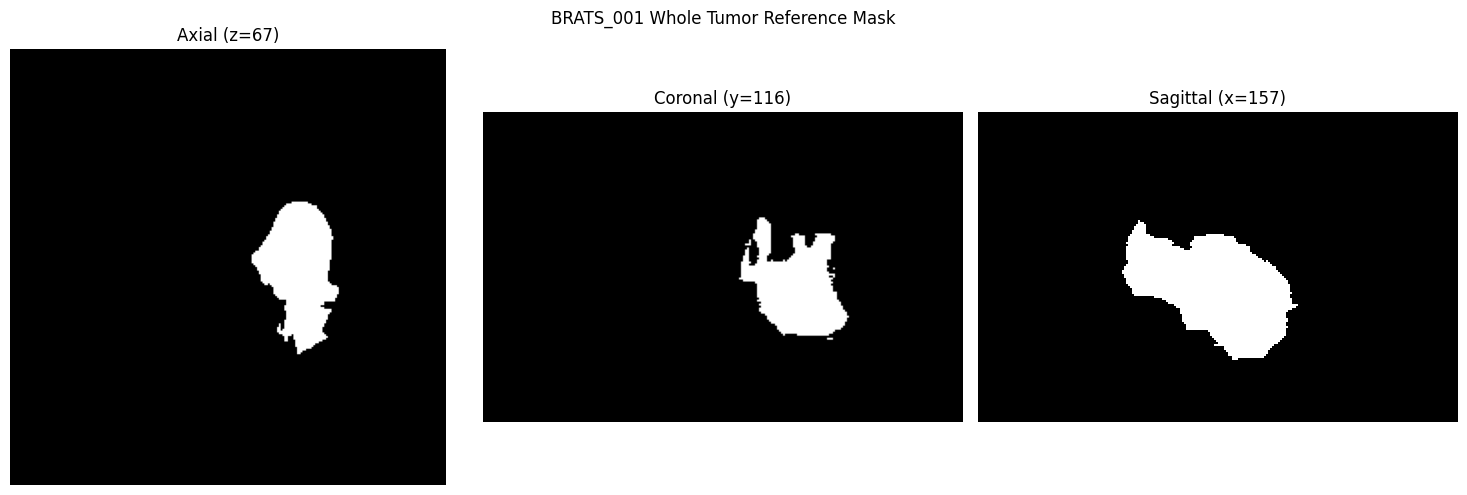

In [4]:
# Find the spatial centroid of the tumor
tumor_voxels = np.argwhere(whole_tumor)
x, y, z = np.rint(tumor_voxels.mean(axis=0)).astype(int)

print("Selected voxel:", (x, y, z))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Axial: XY plane
axes[0].imshow(
    whole_tumor[:, :, z].T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title(f"Axial (z={z})")

# Coronal: XZ plane
axes[1].imshow(
    whole_tumor[:, y, :].T,
    cmap="gray",
    origin="lower"
)
axes[1].set_title(f"Coronal (y={y})")

# Sagittal: YZ plane
axes[2].imshow(
    whole_tumor[x, :, :].T,
    cmap="gray",
    origin="lower"
)
axes[2].set_title(f"Sagittal (x={x})")

for ax in axes:
    ax.axis("off")

plt.suptitle("BRATS_001 Whole Tumor Reference Mask")
plt.tight_layout()
plt.show()

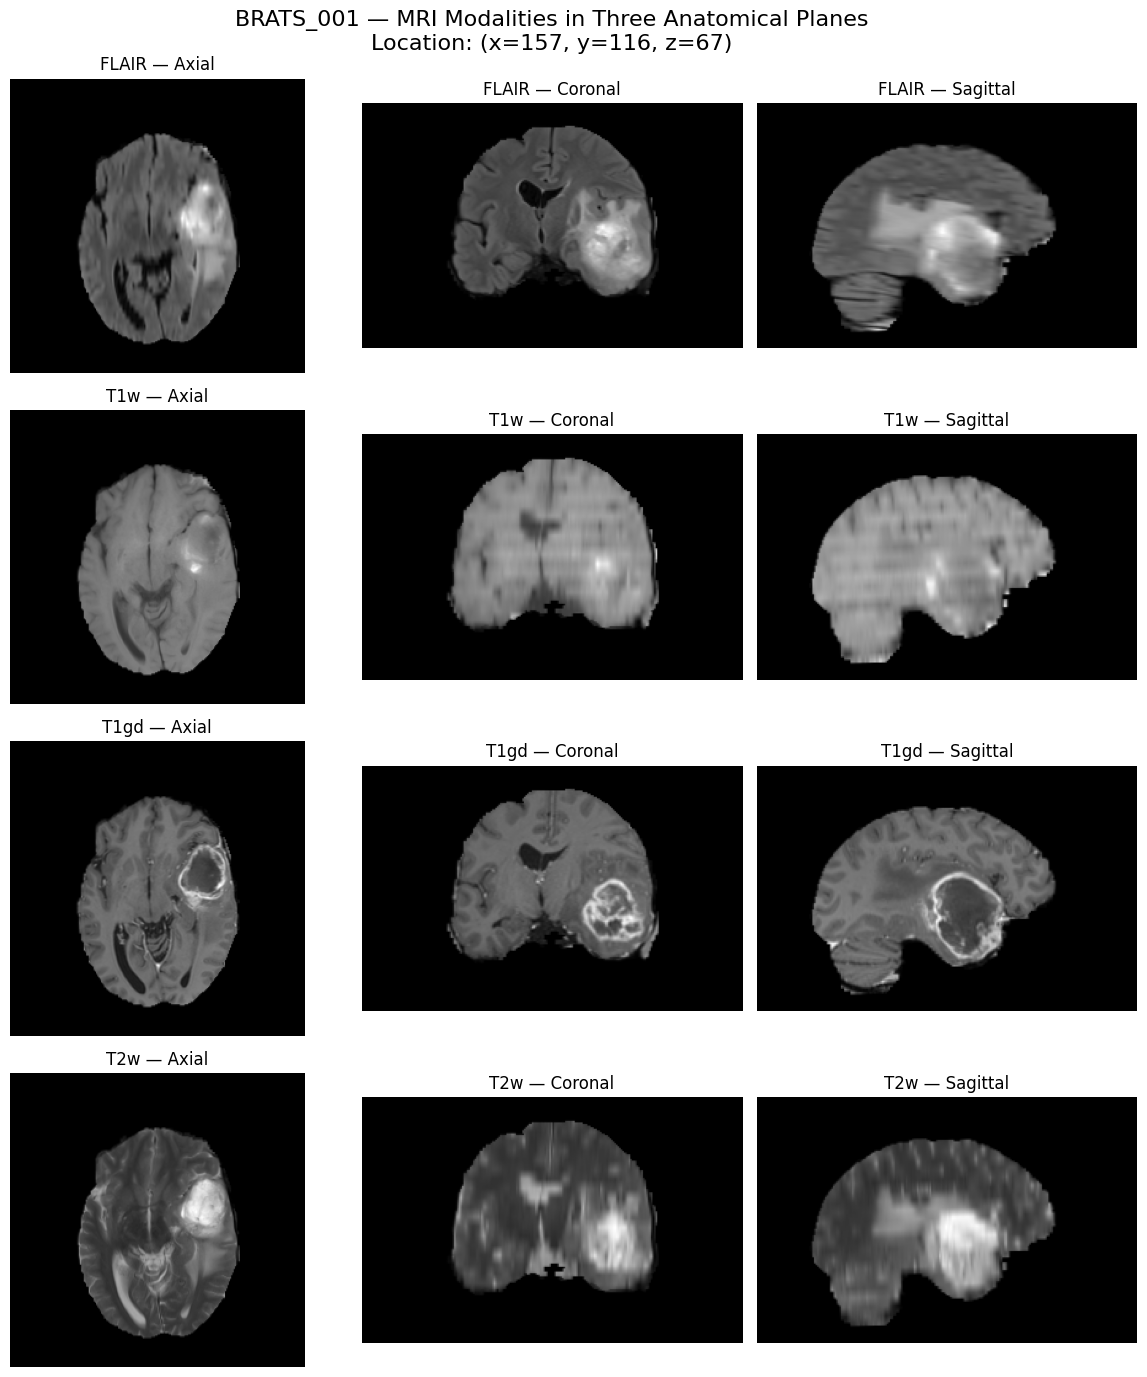

In [5]:
# --------------------------------------------------
# Plot: 4 rows × 3 columns
# --------------------------------------------------

fig, axes = plt.subplots(
    4, 3,
    figsize=(12, 14)
)

for row, (name, volume) in enumerate(modalities.items()):

    # Axial
    axes[row, 0].imshow(
        volume[:, :, z].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 0].set_title(f"{name} — Axial")

    # Coronal
    axes[row, 1].imshow(
        volume[:, y, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 1].set_title(f"{name} — Coronal")

    # Sagittal
    axes[row, 2].imshow(
        volume[x, :, :].T,
        cmap="gray",
        origin="lower"
    )
    axes[row, 2].set_title(f"{name} — Sagittal")

    for col in range(3):
        axes[row, col].axis("off")


plt.suptitle(
    f"BRATS_001 — MRI Modalities in Three Anatomical Planes\n"
    f"Location: (x={x}, y={y}, z={z})",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Data Split

In [6]:
split_df = pd.read_csv("assignment2_split.csv")
display(split_df)

display(split_df['split'].value_counts())

,case_id,split,image_relpath,label_relpath
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz
4,BRATS_005,train,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz
...,...,...,...,...
479,BRATS_480,train,imagesTr/BRATS_480.nii.gz,labelsTr/BRATS_480.nii.gz
480,BRATS_481,test,imagesTr/BRATS_481.nii.gz,labelsTr/BRATS_481.nii.gz
481,BRATS_482,test,imagesTr/BRATS_482.nii.gz,labelsTr/BRATS_482.nii.gz
482,BRATS_483,train,imagesTr/BRATS_483.nii.gz,labelsTr/BRATS_483.nii.gz


split
train         338
test           73
validation     73
Name: count, dtype: int64

In [7]:
def calculate_tumor_volume(label_relpath):
    """Calculate whole-tumor volume in mm³ from a reference mask."""

    label_path = DATA_ROOT / label_relpath

    label_nii = nib.load(label_path)
    label = label_nii.get_fdata()

    # Whole tumor = edema + non-enhancing tumor + enhancing tumor
    whole_tumor = label > 0

    # Voxel spacing in mm
    spacing = label_nii.header.get_zooms()[:3]

    # Volume of one voxel
    voxel_volume = np.prod(spacing)

    # Number of tumor voxels × volume per voxel
    tumor_volume_mm3 = np.sum(whole_tumor) * voxel_volume

    return tumor_volume_mm3

In [8]:
split_df['tumor_volume'] = split_df['label_relpath'].apply(lambda x: calculate_tumor_volume(x))
split_df.head()

,case_id,split,image_relpath,label_relpath,tumor_volume
0,BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz,111724.0
1,BRATS_002,test,imagesTr/BRATS_002.nii.gz,labelsTr/BRATS_002.nii.gz,63061.0
2,BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz,173927.0
3,BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz,120660.0
4,BRATS_005,train,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz,80680.0


In [9]:
train_df = split_df[split_df['split']=='train'].drop('split', axis=1).reset_index(drop=True)
val_df = split_df[split_df['split']=='validation'].drop('split', axis=1).reset_index(drop=True)
test_df = split_df[split_df['split']=='test'].drop('split', axis=1).reset_index(drop=True)

train_ids = set(train_df['case_id'])
val_ids = set(val_df['case_id'])
test_ids = set(test_df['case_id'])
assert train_ids.isdisjoint(val_ids), 'train/validation leakage'
assert train_ids.isdisjoint(test_ids), 'train/test leakage'
assert val_ids.isdisjoint(test_ids), 'validation/test leakage'

print("No intersection in train, val, and test")

print(f"train: {len(train_df)}")
print(f"val: {len(val_df)}")
print(f"test: {len(test_df)}")
train_df.head()

No intersection in train, val, and test
train: 338
val: 73
test: 73


,case_id,image_relpath,label_relpath,tumor_volume
0,BRATS_001,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz,111724.0
1,BRATS_003,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz,173927.0
2,BRATS_004,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz,120660.0
3,BRATS_005,imagesTr/BRATS_005.nii.gz,labelsTr/BRATS_005.nii.gz,80680.0
4,BRATS_007,imagesTr/BRATS_007.nii.gz,labelsTr/BRATS_007.nii.gz,61085.0


Train


count       338.000000
mean     102964.050296
std       56960.257869
min        8478.000000
25%       60023.000000
50%       95484.500000
75%      143920.750000
max      265254.000000
Name: tumor_volume, dtype: float64

Val


count        73.000000
mean     100764.835616
std       62950.123009
min        7285.000000
25%       51853.000000
50%       91560.000000
75%      148062.000000
max      266936.000000
Name: tumor_volume, dtype: float64

<Axes: xlabel='tumor_volume', ylabel='Count'>

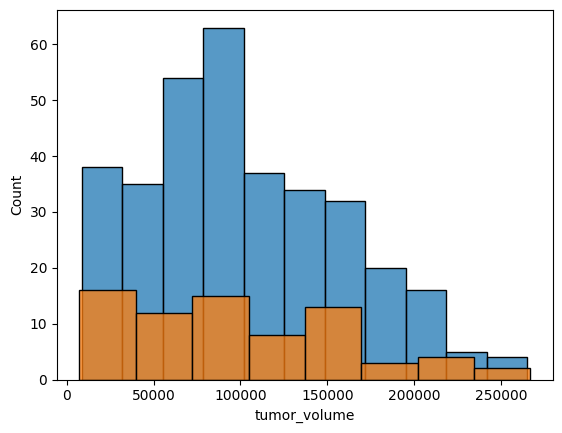

In [10]:
import seaborn as sns

print("Train")
display(train_df['tumor_volume'].describe())

print("Val")
display(val_df['tumor_volume'].describe())

sns.histplot(train_df['tumor_volume'])
sns.histplot(val_df['tumor_volume'])

<Axes: xlabel='tumor_volume', ylabel='Density'>

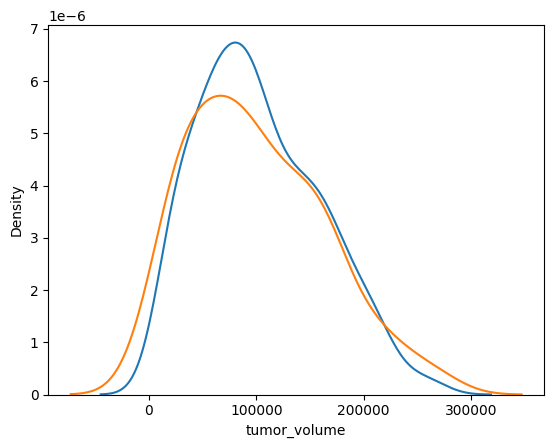

In [11]:
sns.kdeplot(train_df['tumor_volume'])
sns.kdeplot(val_df['tumor_volume'])

## Preprocess and Dataloader

In [12]:
def normalize_image(image):
    """Normalize each MRI channel using its non-zero brain voxels."""
    image = image.clone()
    for c in range(image.shape[0]):
        brain = image[c] != 0  # exclude zero-padded background
        if brain.any():
            mean = image[c][brain].mean()
            std = image[c][brain].std(unbiased=False)
            image[c][brain] = (image[c][brain] - mean) / std.clamp_min(1e-8)
    return image

def augment(image, label, probability=0.5):
    """Apply a paired random left-right flip to a training patch."""
    # [C, D, H, W]: H corresponds to the original NIfTI left-right axis.
    # Avoid superior-inferior flips, which would be anatomically implausible.
    if torch.rand(()) < probability:
        image = torch.flip(image, dims=[2])
        label = torch.flip(label, dims=[2])
    return image, label

In [13]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


class BraTSPatchDataset(Dataset):
    """
    BraTS patch dataset.

    Train:
        Uniformly samples one random patch per case.

    Validation/Test:
        Extracts all patches using a sliding window.

    Image:
        [C, D, H, W]

    Mask:
        [1, D, H, W]
    """

    def __init__(
        self,
        df,
        root_dir,
        patch_size=(96, 96, 96),
        stride=(48, 48, 48),
        train=False,
    ):
        self.df = df.reset_index(drop=True)
        self.root_dir = Path(root_dir)

        self.patch_size = patch_size
        self.stride = stride
        self.train = train

        if train:
            # One randomly sampled patch per dataset item
            self.samples = None
        else:
            # Precompute all sliding-window locations
            self.samples = self._make_sliding_window_index()

    # --------------------------------------------------
    # Basic
    # --------------------------------------------------

    def __len__(self):
        if self.train:
            return len(self.df)

        return len(self.samples)

    # --------------------------------------------------
    # Load one case
    # --------------------------------------------------

    def _load_case(self, case_idx):

        row = self.df.iloc[case_idx]

        image_path = self.root_dir / row["image_relpath"]
        label_path = self.root_dir / row["label_relpath"]

        image = nib.load(image_path).get_fdata()
        label = nib.load(label_path).get_fdata()

        # NIfTI image:
        # [H, W, D, C]
        #
        # Convert to:
        # [C, D, H, W]
        image = np.transpose(image, (3, 2, 0, 1))

        # Label:
        # [H, W, D] -> [D, H, W]
        label = np.transpose(label, (2, 0, 1))

        # Binary segmentation mask
        label = (label > 0).astype(np.float32)

        # Convert to tensors
        image = torch.from_numpy(image.copy()).float()

        label = torch.from_numpy(label.copy()).float()
        label = label.unsqueeze(0)

        # Normalize the full volume before extracting patches.
        image = normalize_image(image)

        # Pad image and mask identically if any dimension is smaller
        # than the requested patch. Existing BraTS volumes need no pad,
        # but this guarantees a fixed output shape for every valid input.
        image, label = self._pad_to_patch_size(image, label)

        return image, label

    # --------------------------------------------------
    # Consistent spatial padding
    # --------------------------------------------------

    def _pad_to_patch_size(self, image, label):
        """Symmetrically zero-pad image and label to at least patch_size."""
        _, D, H, W = image.shape
        pd, ph, pw = self.patch_size

        add_d = max(pd - D, 0)
        add_h = max(ph - H, 0)
        add_w = max(pw - W, 0)

        # F.pad order is (W left/right, H left/right, D left/right).
        padding = (
            add_w // 2, add_w - add_w // 2,
            add_h // 2, add_h - add_h // 2,
            add_d // 2, add_d - add_d // 2,
        )

        if any(padding):
            image = F.pad(image, padding, mode="constant", value=0)
            label = F.pad(label, padding, mode="constant", value=0)

        return image, label

    # --------------------------------------------------
    # Valid patch starts
    # --------------------------------------------------

    def _get_starts(self, size, patch, stride):

        if size <= patch:
            return [0]

        starts = list(range(0, size - patch + 1, stride))

        # Make sure the final part of the volume is covered
        final_start = size - patch

        if starts[-1] != final_start:
            starts.append(final_start)

        return starts

    # --------------------------------------------------
    # Create sliding-window index
    # --------------------------------------------------

    def _make_sliding_window_index(self):

        samples = []

        for case_idx in range(len(self.df)):

            # Load only to determine spatial dimensions
            row = self.df.iloc[case_idx]

            image_path = self.root_dir / row["image_relpath"]

            image = nib.load(image_path)

            # Original shape:
            # [H, W, D, C]
            H, W, D, C = image.shape

            pd, ph, pw = self.patch_size
            sd, sh, sw = self.stride

            d_starts = self._get_starts(D, pd, sd)
            h_starts = self._get_starts(H, ph, sh)
            w_starts = self._get_starts(W, pw, sw)

            for d in d_starts:
                for h in h_starts:
                    for w in w_starts:

                        samples.append(
                            (
                                case_idx,
                                d,
                                h,
                                w,
                            )
                        )

        return samples

    # --------------------------------------------------
    # Extract patch
    # --------------------------------------------------

    def _extract_patch(
        self,
        image,
        label,
        d,
        h,
        w,
    ):

        pd, ph, pw = self.patch_size

        # Identical coordinates keep every MRI channel aligned with its mask.
        image_patch = image[
            :,
            d:d + pd,
            h:h + ph,
            w:w + pw,
        ]

        label_patch = label[
            :,
            d:d + pd,
            h:h + ph,
            w:w + pw,
        ]

        return image_patch, label_patch

    # --------------------------------------------------
    # Uniform random patch
    # --------------------------------------------------

    def _random_patch(self, image, label):

        _, D, H, W = image.shape

        pd, ph, pw = self.patch_size

        # Uniformly sample valid starting coordinates
        d = np.random.randint(0, D - pd + 1)
        h = np.random.randint(0, H - ph + 1)
        w = np.random.randint(0, W - pw + 1)

        return self._extract_patch(
            image,
            label,
            d,
            h,
            w,
        ), (d, h, w)

    # --------------------------------------------------
    # Get item
    # --------------------------------------------------

    def __getitem__(self, idx):

        if self.train:

            # Dataset index corresponds to a case
            case_idx = idx

            image, label = self._load_case(case_idx)

            (image_patch, label_patch), location = self._random_patch(
                image,
                label,
            )

            # Augmentation is training-only and keeps image/mask aligned.
            image_patch, label_patch = augment(image_patch, label_patch)

        else:

            # Sliding-window evaluation
            case_idx, d, h, w = self.samples[idx]

            image, label = self._load_case(case_idx)

            image_patch, label_patch = self._extract_patch(
                image,
                label,
                d,
                h,
                w,
            )

            location = (d, h, w)

        return {
            "image": image_patch,
            "mask": label_patch,
            "case_idx": case_idx,
            "location": location,
        }

In [14]:
PATCH_SIZE = (96, 96, 96)
STRIDE = (48, 48, 48)

train_dataset = BraTSPatchDataset(
    train_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    train=True,
)

val_dataset = BraTSPatchDataset(
    val_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    train=False,
)

test_dataset = BraTSPatchDataset(
    test_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    train=False,
)

In [15]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
)

Raw shape: torch.Size([240, 240, 155, 4])
Raw min/max: 0.0 2346.0
Processed shape: torch.Size([4, 155, 240, 240])
Processed min/max: -4.142197132110596 8.075838088989258

Post-normalization statistics (non-zero brain voxels):
FLAIR: mean= 0.0000, std=1.0000
T1w  : mean=-0.0000, std=1.0000
T1gd : mean=-0.0000, std=1.0000
T2w  : mean= 0.0000, std=1.0000


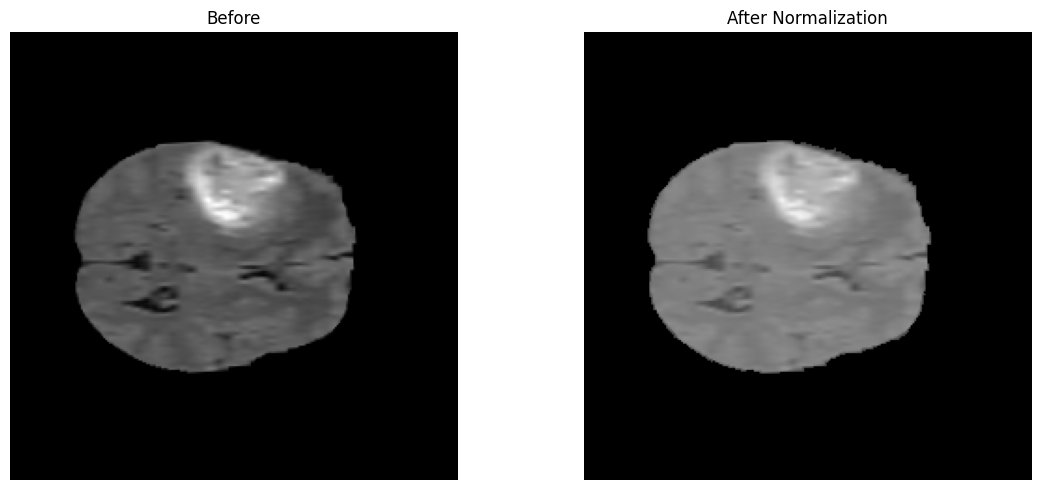

In [16]:
image_nii = nib.load(DATA_ROOT / train_df['image_relpath'][2])
label_nii = nib.load(DATA_ROOT / train_df['label_relpath'][2])

image_raw = torch.from_numpy(image_nii.get_fdata()).float()
label = torch.from_numpy(label_nii.get_fdata()).float()

print("Raw shape:", image_raw.shape)
print("Raw min/max:", image_raw.min().item(), image_raw.max().item())

# -------------------------
# After dataset preprocessing
# -------------------------

# Raw NIfTI: [H, W, D, C]
image_processed = torch.from_numpy(
    image_nii.get_fdata().copy()
).float()

# -> [C, D, H, W]
image_processed = torch.permute(
    image_processed, (3, 2, 0, 1)
)

# [H, W, D] -> [D, H, W]
label = torch.permute(label, (2, 0, 1))

# [D, H, W] -> [1, D, H, W]
label = label.unsqueeze(0)

# Preserve the original brain mask for reporting, then normalize.
brain_masks = image_processed != 0
image_processed = normalize_image(image_processed)

print("Processed shape:", image_processed.shape)
print(
    "Processed min/max:",
    image_processed.min().item(),
    image_processed.max().item()
)

print("\nPost-normalization statistics (non-zero brain voxels):")
for channel, name in enumerate(modalities):
    brain = brain_masks[channel]
    channel_values = image_processed[channel][brain]
    print(
        f"{name:5s}: mean={channel_values.mean().item(): .4f}, "
        f"std={channel_values.std(unbiased=False).item():.4f}"
    )


# -------------------------
# Display
# -------------------------

modality = 0
slice_idx = image_raw.shape[2] // 2

# Raw is [H, W, D, C]
before = image_raw[:, :, slice_idx, modality]

# Processed is [C, D, H, W]
after = image_processed[modality, slice_idx]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(before, cmap="gray")
ax[0].set_title("Before")
ax[0].axis("off")

after_np = after.cpu().numpy()
masked = np.ma.masked_where(after_np == 0, after_np)

cmap = plt.cm.gray.copy()
cmap.set_bad("black")
v = float(image_processed[modality].abs().max()) or 1.0

ax[1].imshow(masked, cmap=cmap, vmin=-v, vmax=v)
# ax[1].imshow(after, cmap="gray", vmin=-v, vmax=v)
ax[1].set_title("After Normalization")
ax[1].axis("off")

plt.tight_layout()
plt.show()

### Consistent crop/pad and safe augmentation

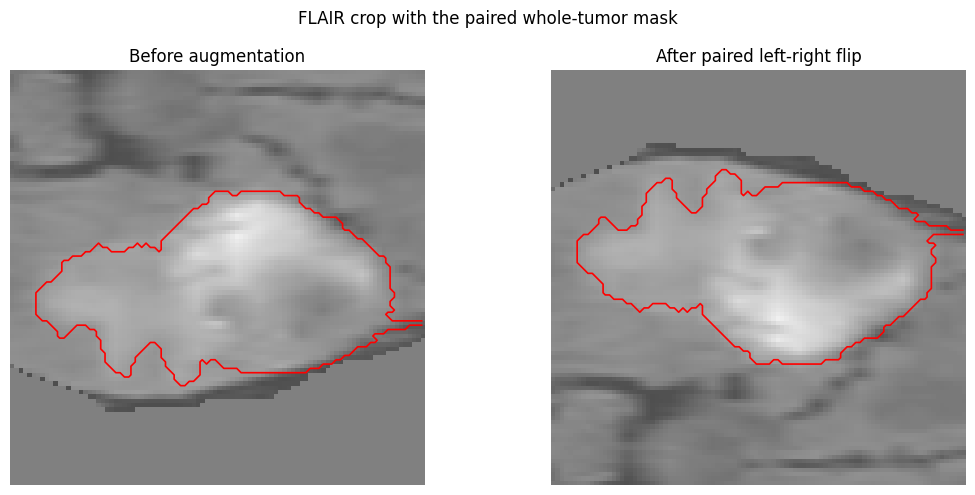

Before shapes: torch.Size([4, 96, 96, 96]) torch.Size([1, 96, 96, 96])
After shapes:  torch.Size([4, 96, 96, 96]) torch.Size([1, 96, 96, 96])
Mask values after augmentation: [0.0, 1.0]


In [17]:
# Build a tumor-centred crop so the paired augmentation is easy to inspect.
example_image, example_mask = train_dataset._load_case(0)
tumor_coordinates = torch.nonzero(example_mask[0] > 0, as_tuple=False)
tumor_centre = tumor_coordinates.float().mean(dim=0).round().long()

crop_start = []
for centre, size, patch in zip(
    tumor_centre.tolist(), example_image.shape[1:], PATCH_SIZE
):
    crop_start.append(max(0, min(centre - patch // 2, size - patch)))

before_image, before_mask = train_dataset._extract_patch(
    example_image, example_mask, *crop_start
)

# Force the same safe transform used in training so it is visible here.
after_image, after_mask = augment(
    before_image.clone(), before_mask.clone(), probability=1.0
)

slice_idx = int(before_mask[0].sum(dim=(1, 2)).argmax())
channel = 0  # FLAIR
v = float(before_image[channel].abs().max()) or 1.0

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
paired = [
    (before_image, before_mask, "Before augmentation"),
    (after_image, after_mask, "After paired left-right flip"),
]

for ax, (patch_image, patch_mask, title) in zip(axes, paired):
    image_slice = patch_image[channel, slice_idx].cpu().numpy()
    mask_slice = patch_mask[0, slice_idx].cpu().numpy()
    ax.imshow(image_slice, cmap="gray", vmin=-v, vmax=v)
    ax.contour(mask_slice, levels=[0.5], colors="red", linewidths=1.2)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("FLAIR crop with the paired whole-tumor mask")
plt.tight_layout()
plt.show()

print("Before shapes:", before_image.shape, before_mask.shape)
print("After shapes: ", after_image.shape, after_mask.shape)
print("Mask values after augmentation:", torch.unique(after_mask).tolist())

In [18]:
#single batch shape

train_batch = next(iter(train_loader))
val_batch = next(iter(val_loader))

print("Train:")
print("  Images:", train_batch["image"].shape)
print("  Masks: ", train_batch["mask"].shape)

print("\nValidation:")
print("  Images:", val_batch["image"].shape)
print("  Masks: ", val_batch["mask"].shape)

Train:
  Images: torch.Size([4, 4, 96, 96, 96])
  Masks:  torch.Size([4, 1, 96, 96, 96])

Validation:
  Images: torch.Size([4, 4, 96, 96, 96])
  Masks:  torch.Size([4, 1, 96, 96, 96])


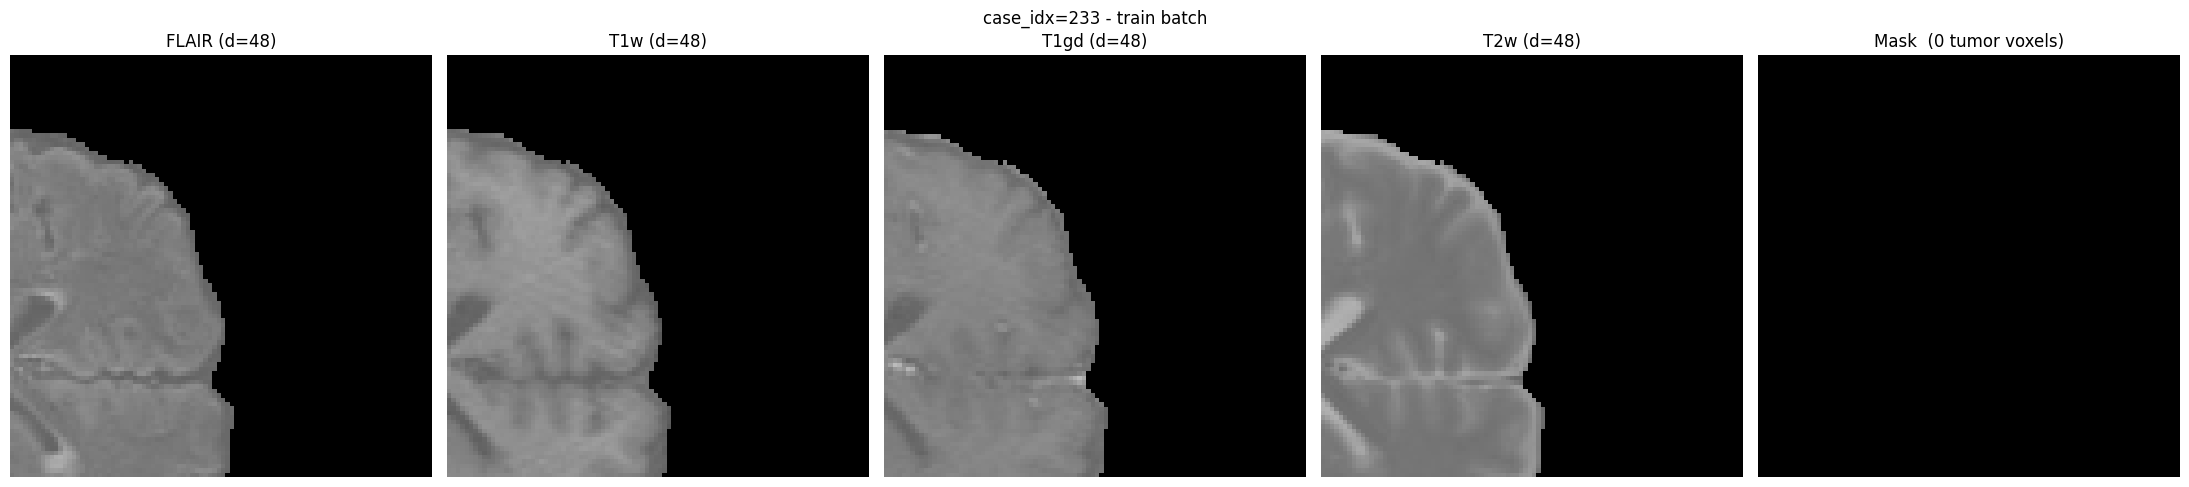

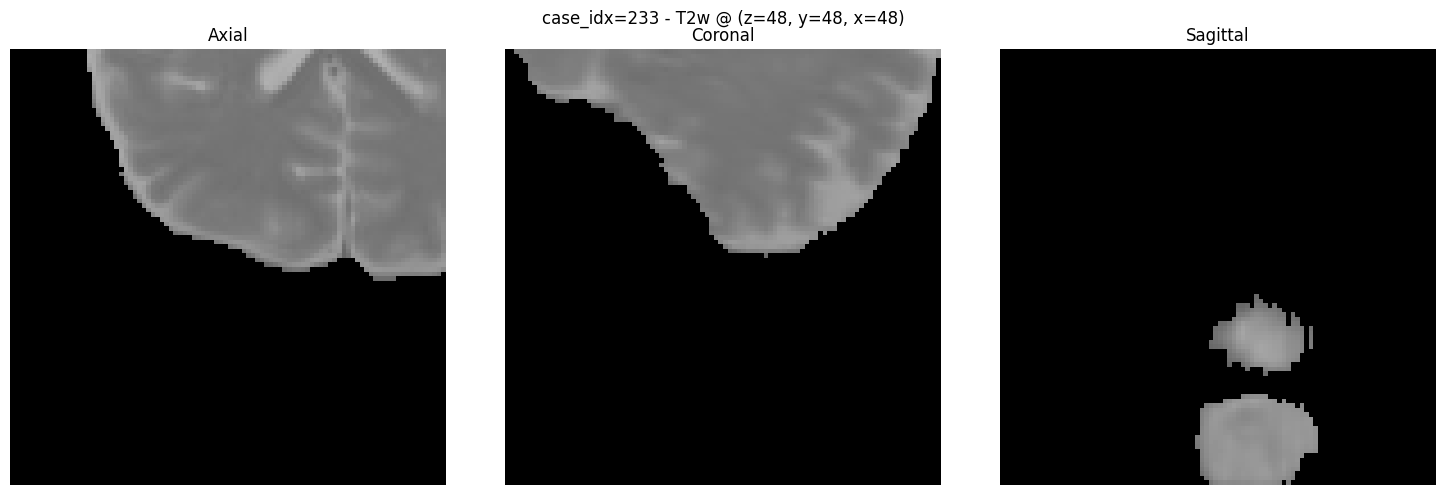

In [19]:
def _to_numpy(t):
    """Detach a tensor and move it to CPU as a numpy array."""
    return t.detach().cpu().numpy()


def _best_slice(mask_3d):
    """
    Pick the axial slice with the most tumor.

    Returns the middle slice if the patch is all background (common for
    sliding-window validation patches).
    """
    if mask_3d.sum() == 0:
        return mask_3d.shape[0] // 2
    return int(mask_3d.sum(axis=(1, 2)).argmax())


def _gray_with_background():
    """Grayscale colormap where masked-out voxels render as black."""
    cmap = plt.cm.gray.copy()
    cmap.set_bad("black")
    return cmap


def show_case(image, mask, case_idx, d=None, title=""):
    """
    All 4 modalities + the mask for one item of a batch, with a red
    whole-tumor contour overlaid.

    image: [C, D, H, W]
    mask:  [1, D, H, W]
    """
    image = _to_numpy(image)
    mask = _to_numpy(mask)[0]  # -> [D, H, W]

    if d is None:
        d = _best_slice(mask)

    v = float(np.abs(image).max()) or 1.0
    cmap = _gray_with_background()

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    for ax, name, c in zip(axes[:4], list(modalities.keys()), range(image.shape[0])):
        sl = image[c, d]
        ax.imshow(np.ma.masked_where(sl == 0, sl), cmap=cmap, vmin=-v, vmax=v)
        ax.contour(mask[d], levels=[0.5], colors="red", linewidths=1.2)
        ax.set_title(f"{name} (d={d})")
        ax.axis("off")

    axes[4].imshow(mask[d], cmap="gray")
    axes[4].set_title(f"Mask  ({mask.sum():.0f} tumor voxels)")
    axes[4].axis("off")

    fig.suptitle(f"case_idx={case_idx} - {title}")
    plt.tight_layout()
    plt.show()


def show_ortho(image, mask, case_idx, channel=3):
    """
    Axial / coronal / sagittal views through the tumor centre.

    image: [C, D, H, W]
    mask:  [1, D, H, W]
    channel: modality index (3 = T2w)
    """
    image = _to_numpy(image)
    mask = _to_numpy(mask)[0]

    if mask.sum() > 0:
        z, y, x = np.rint(np.argwhere(mask > 0).mean(axis=0)).astype(int)
    else:
        z, y, x = [s // 2 for s in mask.shape]

    v = float(np.abs(image).max()) or 1.0
    cmap = _gray_with_background()

    img = image[channel]

    views = [
        ("Axial", img[z], mask[z]),
        ("Coronal", img[:, y, :], mask[:, y, :]),
        ("Sagittal", img[:, :, x], mask[:, :, x]),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (name, sl, msk) in zip(axes, views):
        ax.imshow(np.ma.masked_where(sl.T == 0, sl.T), cmap=cmap, vmin=-v, vmax=v)
        ax.contour(msk.T, levels=[0.5], colors="red", linewidths=1.2)
        ax.set_title(name)
        ax.axis("off")

    fig.suptitle(f"case_idx={case_idx} - {list(modalities.keys())[channel]} @ (z={z}, y={y}, x={x})")
    plt.tight_layout()
    plt.show()


def show_batch(batch, title="batch", b=0):
    """show_case() for one specific item of a batch."""
    show_case(
        batch["image"][b],
        batch["mask"][b],
        batch["case_idx"][b],
        title=title,
    )


def show_batch_grid(batch, title="batch"):
    """
    Rows = items in the batch, columns = the 4 modalities.
    Each panel uses that item's own tumor-heavy slice.
    """
    img_all = _to_numpy(batch["image"])  # [B, C, D, H, W]
    msk_all = _to_numpy(batch["mask"])[:, 0]  # [B, D, H, W]

    n = img_all.shape[0]
    fig, axes = plt.subplots(n, 4, figsize=(18, 4.5 * n), squeeze=False)

    for b in range(n):
        img = img_all[b]
        msk = msk_all[b]
        d = _best_slice(msk)
        v = float(np.abs(img).max()) or 1.0
        cmap = _gray_with_background()

        for c in range(4):
            ax = axes[b, c]
            sl = img[c, d]
            ax.imshow(np.ma.masked_where(sl == 0, sl), cmap=cmap, vmin=-v, vmax=v)
            ax.contour(msk[d], levels=[0.5], colors="red", linewidths=1.0)
            ax.set_title(f"b{b} {list(modalities.keys())[c]}")
            ax.axis("off")

    fig.suptitle(f"{title} - 4 modalities x {n} items")
    plt.tight_layout()
    plt.show()

show_batch(train_batch, title="train batch", b=0)
show_ortho(train_batch["image"][0], train_batch["mask"][0], train_batch["case_idx"][0])
# show_batch_grid(train_batch, title="train batch")

## Training

In [20]:
import copy
import random
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

# Controlled experiment configuration
SEED = 42
INPUT_CHANNELS = 4
OUTPUT_CHANNELS = 1
BASE_CHANNELS = 8
TRAIN_BATCH_SIZE = 1
EPOCHS = 10
TRAIN_STEPS_PER_EPOCH = 50
ITERATION_BUDGET = EPOCHS * TRAIN_STEPS_PER_EPOCH
VALIDATION_PATCHES = 64
LEARNING_RATE = 1e-3
TUMOR_SAMPLING_PROBABILITY = 0.75
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class ConvBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv3d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels),
            nn.LeakyReLU(0.1, inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class LightweightUNet3D(nn.Module):
    """Two-level fully convolutional 3D U-Net for binary segmentation."""
    def __init__(self, in_channels=4, out_channels=1, base_channels=8):
        super().__init__()
        b = base_channels
        self.enc1 = ConvBlock3D(in_channels, b)
        self.enc2 = ConvBlock3D(b, 2 * b)
        self.bottleneck = ConvBlock3D(2 * b, 4 * b)
        self.pool = nn.MaxPool3d(2)
        self.up2 = nn.ConvTranspose3d(4 * b, 2 * b, 2, stride=2)
        self.dec2 = ConvBlock3D(4 * b, 2 * b)
        self.up1 = nn.ConvTranspose3d(2 * b, b, 2, stride=2)
        self.dec1 = ConvBlock3D(2 * b, b)
        self.output = nn.Conv3d(b, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        bottleneck = self.bottleneck(self.pool(e2))
        d2 = self.dec2(torch.cat([self.up2(bottleneck), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output(d1)


set_seed(SEED)
initial_model = LightweightUNet3D(
    INPUT_CHANNELS, OUTPUT_CHANNELS, BASE_CHANNELS
)
INITIAL_STATE = copy.deepcopy(initial_model.state_dict())
PARAMETER_COUNT = sum(p.numel() for p in initial_model.parameters() if p.requires_grad)

print(f"Input channels: {INPUT_CHANNELS}")
print(f"Output channels: {OUTPUT_CHANNELS}")
print(f"Trainable parameters: {PARAMETER_COUNT:,}")
print(f"Patch size: {PATCH_SIZE}")
print(f"Seed: {SEED}")
print(f"Budget per sampler: {EPOCHS} epochs x {TRAIN_STEPS_PER_EPOCH} steps = {ITERATION_BUDGET} updates")

Device: cuda
GPU: NVIDIA RTX 5000 Ada Generation
Input channels: 4
Output channels: 1
Trainable parameters: 85,825
Patch size: (96, 96, 96)
Seed: 42
Budget per sampler: 10 epochs x 50 steps = 500 updates


In [21]:
class TrainingPatchDataset(BraTSPatchDataset):
    """Training dataset supporting controlled uniform/tumor-aware crops."""
    def __init__(self, *args, sampling="uniform", tumor_probability=0.75, **kwargs):
        super().__init__(*args, train=True, **kwargs)
        if sampling not in {"uniform", "tumor_aware"}:
            raise ValueError("sampling must be 'uniform' or 'tumor_aware'")
        self.sampling = sampling
        self.tumor_probability = tumor_probability
        self.sampled_patches = 0
        self.tumor_patches = 0

    @staticmethod
    def _start_containing(voxel, size, patch):
        low = max(0, voxel - patch + 1)
        high = min(voxel, size - patch)
        return np.random.randint(low, high + 1)

    def _random_patch(self, image, label):
        _, D, H, W = image.shape
        pd, ph, pw = self.patch_size
        choose_tumor = (
            self.sampling == "tumor_aware"
            and label.any().item()
            and np.random.random() < self.tumor_probability
        )

        if choose_tumor:
            tumor_voxels = torch.nonzero(label[0] > 0, as_tuple=False)
            voxel = tumor_voxels[np.random.randint(len(tumor_voxels))].tolist()
            d = self._start_containing(voxel[0], D, pd)
            h = self._start_containing(voxel[1], H, ph)
            w = self._start_containing(voxel[2], W, pw)
        else:
            d = np.random.randint(0, D - pd + 1)
            h = np.random.randint(0, H - ph + 1)
            w = np.random.randint(0, W - pw + 1)

        patches = self._extract_patch(image, label, d, h, w)
        return patches, (d, h, w)

    def __getitem__(self, idx):
        sample = super().__getitem__(idx)
        self.sampled_patches += 1
        self.tumor_patches += int(sample["mask"].any().item())
        return sample

    @property
    def tumor_patch_fraction(self):
        return self.tumor_patches / max(self.sampled_patches, 1)


uniform_train_dataset = TrainingPatchDataset(
    train_df, DATA_ROOT, patch_size=PATCH_SIZE, sampling="uniform"
)
tumor_train_dataset = TrainingPatchDataset(
    train_df, DATA_ROOT, patch_size=PATCH_SIZE, sampling="tumor_aware",
    tumor_probability=TUMOR_SAMPLING_PROBABILITY,
)

# Fixed, evenly spaced validation patches are shared by both experiments.
validation_indices = np.linspace(
    0, len(val_dataset) - 1, min(VALIDATION_PATCHES, len(val_dataset)), dtype=int
).tolist()
fixed_validation_dataset = Subset(val_dataset, validation_indices)
validation_loader = DataLoader(
    fixed_validation_dataset, batch_size=1, shuffle=False, num_workers=4,
    pin_memory=(DEVICE.type == "cuda"),
)

In [22]:
class BCEDiceLoss(nn.Module):
    """Equal-weight binary cross-entropy and soft Dice loss."""
    def __init__(self, smooth=1e-5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def forward(self, logits, targets):
        probabilities = torch.sigmoid(logits)
        dims = tuple(range(1, targets.ndim))
        intersection = (probabilities * targets).sum(dim=dims)
        denominator = probabilities.sum(dim=dims) + targets.sum(dim=dims)
        dice_loss = 1 - ((2 * intersection + self.smooth) / (denominator + self.smooth)).mean()
        return 0.5 * self.bce(logits, targets) + 0.5 * dice_loss


def binary_dice_counts(logits, targets, threshold=0.5):
    predictions = (torch.sigmoid(logits) >= threshold).float()
    intersection = (predictions * targets).sum().item()
    predicted = predictions.sum().item()
    target = targets.sum().item()
    return intersection, predicted, target


@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_intersection = total_predicted = total_target = 0.0

    for batch in loader:
        images = batch["image"].to(DEVICE, non_blocking=True)
        masks = batch["mask"].to(DEVICE, non_blocking=True)
        logits = model(images)
        total_loss += criterion(logits, masks).item()
        intersection, predicted, target = binary_dice_counts(logits, masks)
        total_intersection += intersection
        total_predicted += predicted
        total_target += target

    mean_loss = total_loss / len(loader)
    dice = (2 * total_intersection + 1e-5) / (total_predicted + total_target + 1e-5)
    return mean_loss, dice


def train_experiment(name, dataset):
    # Identical seed, initialization, optimizer and update budget for both samplers.
    set_seed(SEED)
    dataset.sampled_patches = 0
    dataset.tumor_patches = 0
    total_sampled_patches = 0
    total_tumor_patches = 0

    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(
        dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=4,
        pin_memory=(DEVICE.type == "cuda"), generator=generator,
    )

    model = LightweightUNet3D(INPUT_CHANNELS, OUTPUT_CHANNELS, BASE_CHANNELS)
    model.load_state_dict(copy.deepcopy(INITIAL_STATE))
    model = model.to(DEVICE)
    criterion = BCEDiceLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best_dice = -1.0
    best_state = None

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        iterator = iter(loader)

        for _ in range(TRAIN_STEPS_PER_EPOCH):
            try:
                batch = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                batch = next(iterator)

            images = batch["image"].to(DEVICE, non_blocking=True)
            masks = batch["mask"].to(DEVICE, non_blocking=True)

            # Count the masks that actually enter training. This works with
            # any batch size and with multiple DataLoader worker processes.
            contains_tumor = masks.flatten(start_dim=1).any(dim=1)
            total_sampled_patches += masks.shape[0]
            total_tumor_patches += contains_tumor.sum().item()
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        train_loss = running_loss / TRAIN_STEPS_PER_EPOCH
        val_loss, val_dice = validate(model, validation_loader, criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        if val_dice > best_dice:
            best_dice = val_dice
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            checkpoint_path = MODEL_DIR / f"{name.replace('-', '_')}_best.pt"
            torch.save({
                "sampler": name,
                "epoch": epoch + 1,
                "best_val_dice": best_dice,
                "model_state_dict": best_state,
                "input_channels": INPUT_CHANNELS,
                "output_channels": OUTPUT_CHANNELS,
                "base_channels": BASE_CHANNELS,
                "patch_size": PATCH_SIZE,
                "seed": SEED,
            }, checkpoint_path)

        print(
            f"{name:11s} | epoch {epoch + 1}/{EPOCHS} | "
            f"train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
            f"val Dice {val_dice:.4f}"
        )

    model.load_state_dict(best_state)  # selected using validation Dice only
    tumor_fraction = total_tumor_patches / max(total_sampled_patches, 1)

    # Copy the main-process totals back for the summary table below.
    dataset.sampled_patches = total_sampled_patches
    dataset.tumor_patches = total_tumor_patches

    print(f"{name} tumor-containing patch fraction: {tumor_fraction:.3f}")
    return model, history, tumor_fraction


print("Loss: 0.5 * BCEWithLogitsLoss + 0.5 * soft Dice loss")
print(f"Optimizer: Adam | learning rate: {LEARNING_RATE}")
print(f"Seed: {SEED} | update budget per run: {ITERATION_BUDGET}")

Loss: 0.5 * BCEWithLogitsLoss + 0.5 * soft Dice loss
Optimizer: Adam | learning rate: 0.001
Seed: 42 | update budget per run: 500


In [23]:
# # Run the controlled experiments. The test split is not accessed here.
# uniform_model, uniform_history, uniform_tumor_fraction = train_experiment(
#     "uniform", uniform_train_dataset
# )
# tumor_model, tumor_history, tumor_aware_fraction = train_experiment(
#     "tumor-aware", tumor_train_dataset
# )

# sampling_results = pd.DataFrame({
#     "sampler": ["uniform", "tumor-aware"],
#     "sampled_patches": [
#         uniform_train_dataset.sampled_patches,
#         tumor_train_dataset.sampled_patches,
#     ],
#     "fraction_containing_tumor": [
#         uniform_tumor_fraction, tumor_aware_fraction,
#     ],
# })
# display(sampling_results)

# # Select between the two controlled runs using validation Dice only.
# experiment_results = {
#     "uniform": (uniform_model, uniform_history),
#     "tumor-aware": (tumor_model, tumor_history),
# }
# best_sampler = max(
#     experiment_results,
#     key=lambda name: max(experiment_results[name][1]["val_dice"]),
# )
# best_model, best_history = experiment_results[best_sampler]
# best_epoch = int(np.argmax(best_history["val_dice"])) + 1
# best_val_dice = float(max(best_history["val_dice"]))
# best_model_state = {
#     key: value.detach().cpu().clone()
#     for key, value in best_model.state_dict().items()
# }
# best_model_path = MODEL_DIR / "best_model.pt"
# torch.save({
#     "sampler": best_sampler,
#     "epoch": best_epoch,
#     "best_val_dice": best_val_dice,
#     "model_state_dict": best_model_state,
#     "input_channels": INPUT_CHANNELS,
#     "output_channels": OUTPUT_CHANNELS,
#     "base_channels": BASE_CHANNELS,
#     "patch_size": PATCH_SIZE,
#     "seed": SEED,
# }, best_model_path)
# print(
#     f"Saved overall best model to {best_model_path} "
#     f"({best_sampler}, epoch {best_epoch}, validation Dice={best_val_dice:.4f})"
# )

In [24]:
# epochs = np.arange(1, EPOCHS + 1)
# fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# for name, history in [
#     ("Uniform", uniform_history),
#     ("Tumor-aware", tumor_history),
# ]:
#     axes[0].plot(epochs, history["train_loss"], marker="o", label=name)
#     axes[1].plot(epochs, history["val_loss"], marker="o", label=name)
#     axes[2].plot(epochs, history["val_dice"], marker="o", label=name)

# axes[0].set_title("Training loss")
# axes[1].set_title("Validation loss")
# axes[2].set_title("Validation Dice")
# axes[2].set_ylim(0, 1)
# for ax in axes:
#     ax.set_xlabel("Epoch")
#     ax.grid(alpha=0.3)
#     ax.legend()
# plt.tight_layout()
# plt.show()


# def diagnose_training(name, history):
#     train = np.asarray(history["train_loss"])
#     val = np.asarray(history["val_loss"])
#     dice = np.asarray(history["val_dice"])
#     best_epoch = int(dice.argmax()) + 1

#     if len(val) > 2 and np.std(np.diff(val)) > 0.15 * max(abs(val.mean()), 1e-8):
#         diagnosis = "training appears unstable because validation loss fluctuates strongly"
#     elif val[-1] > val.min() * 1.10 and train[-1] < train[0] * 0.80:
#         diagnosis = "possible overfitting: training loss fell while validation loss rose from its minimum"
#     elif dice.max() < 0.30 and train[-1] > 0.50:
#         diagnosis = "likely underfitting at this budget: both loss and validation Dice remain weak"
#     else:
#         diagnosis = "no clear instability or overfitting signal within this training budget"

#     print(
#         f"{name}: best validation Dice={dice.max():.4f} at epoch {best_epoch}; "
#         f"{diagnosis}."
#     )


# diagnose_training("Uniform", uniform_history)
# diagnose_training("Tumor-aware", tumor_history)
# print("Model selection and diagnosis used validation metrics only; test results were not used.")

## Evaluate

### Uniform and Tumor Aware

In [25]:
def load_model(path):
    model = LightweightUNet3D(
        INPUT_CHANNELS, OUTPUT_CHANNELS, BASE_CHANNELS
    )

    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    return model


uniform_model = load_model(MODEL_DIR / "uniform_best.pt")
tumor_model = load_model(MODEL_DIR / "tumor_aware_best.pt")

In [76]:
import time
from scipy.ndimage import binary_erosion, distance_transform_edt


def compute_hd95_mm(prediction, target, spacing_dhw):
    """Calculate symmetric HD95 between binary masks in millimetres.

    Parameters
    ----------
    prediction, target : array-like, shape (D, H, W)
        Binary segmentation masks.
    spacing_dhw : tuple
        Physical voxel spacing corresponding to the array axes (D, H, W).

    Returns
    -------
    float
        Symmetric 95th-percentile Hausdorff distance. Returns:
        - 0.0 if both masks are empty
        - np.inf if exactly one mask is empty
    """
    prediction = np.asarray(prediction, dtype=bool)
    target = np.asarray(target, dtype=bool)

    prediction_nonempty = prediction.any()
    target_nonempty = target.any()

    if not prediction_nonempty and not target_nonempty:
        return 0.0

    if prediction_nonempty != target_nonempty:
        return np.inf

    structure = np.ones((3, 3, 3), dtype=bool)

    prediction_surface = prediction & ~binary_erosion(
        prediction, structure=structure, border_value=0
    )
    target_surface = target & ~binary_erosion(
        target, structure=structure, border_value=0
    )

    # Each distance map gives the physical distance to the nearest surface voxel.
    distance_to_target = distance_transform_edt(
        ~target_surface, sampling=spacing_dhw
    )
    distance_to_prediction = distance_transform_edt(
        ~prediction_surface, sampling=spacing_dhw
    )

    prediction_to_target = distance_to_target[prediction_surface]
    target_to_prediction = distance_to_prediction[target_surface]

    surface_distances = np.concatenate(
        [prediction_to_target, target_to_prediction]
    )
    return float(np.percentile(surface_distances, 95))


@torch.inference_mode()
def evaluate_validation_model(
    model,
    dataset,
    model_name,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
    postprocess_fn=None,
    postprocess_kwargs=None,
):
    """Reconstruct volumes and calculate case-level whole-tumor metrics.

    If postprocess_fn is supplied, it is applied to the thresholded 3D
    prediction before all metrics and volumes are calculated.
    """
    device = torch.device(device)
    model = model.to(device)
    model.eval()

    if postprocess_kwargs is None:
        postprocess_kwargs = {}

    rows = []
    patch_d, patch_h, patch_w = dataset.patch_size
    use_amp = device.type == "cuda"

    for case_idx in range(len(dataset.df)):
        start_time = time.perf_counter()

        image, target = dataset._load_case(case_idx)
        _, D, H, W = image.shape

        d_starts = dataset._get_starts(
            D, patch_d, dataset.stride[0]
        )
        h_starts = dataset._get_starts(
            H, patch_h, dataset.stride[1]
        )
        w_starts = dataset._get_starts(
            W, patch_w, dataset.stride[2]
        )

        locations = [
            (d, h, w)
            for d in d_starts
            for h in h_starts
            for w in w_starts
        ]

        probability_sum = torch.zeros(
            (1, D, H, W),
            dtype=torch.float32,
        )
        prediction_count = torch.zeros_like(probability_sum)

        for start in range(0, len(locations), batch_size):
            location_batch = locations[start:start + batch_size]

            image_batch = torch.stack([
                dataset._extract_patch(
                    image, target, d, h, w
                )[0]
                for d, h, w in location_batch
            ]).to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp,
            ):
                probabilities = torch.sigmoid(
                    model(image_batch)
                )

            probabilities = probabilities.float().cpu()

            for probability, (d, h, w) in zip(
                probabilities,
                location_batch,
            ):
                probability_sum[
                    :,
                    d:d + patch_d,
                    h:h + patch_h,
                    w:w + patch_w,
                ] += probability

                prediction_count[
                    :,
                    d:d + patch_d,
                    h:h + patch_h,
                    w:w + patch_w,
                ] += 1

        mean_probability = probability_sum.div(
            prediction_count.clamp_min(1)
        )

        prediction = mean_probability.ge(threshold)
        target_binary = target.ge(0.5)

        # Save the number of positive voxels before postprocessing.
        predicted_voxels_before_postprocessing = int(
            prediction.sum().item()
        )

        # Apply optional connected-component postprocessing.
        if postprocess_fn is not None:
            prediction_np = (
                prediction.squeeze(0)
                .cpu()
                .numpy()
                .astype(bool)
            )

            prediction_np = postprocess_fn(
                prediction_np,
                **postprocess_kwargs,
            )

            prediction = torch.from_numpy(
                prediction_np
            ).bool().unsqueeze(0)

        true_positive = int(
            torch.logical_and(
                prediction, target_binary
            ).sum().item()
        )
        false_positive = int(
            torch.logical_and(
                prediction, ~target_binary
            ).sum().item()
        )
        false_negative = int(
            torch.logical_and(
                ~prediction, target_binary
            ).sum().item()
        )
        true_negative = int(
            torch.logical_and(
                ~prediction, ~target_binary
            ).sum().item()
        )

        predicted_voxels = int(prediction.sum().item())
        reference_voxels = int(target_binary.sum().item())
        empty_prediction = predicted_voxels == 0

        removed_voxels = (
            predicted_voxels_before_postprocessing
            - predicted_voxels
        )

        dice_denominator = (
            2 * true_positive
            + false_positive
            + false_negative
        )
        iou_denominator = (
            true_positive
            + false_positive
            + false_negative
        )
        sensitivity_denominator = (
            true_positive + false_negative
        )

        dice = (
            2 * true_positive / dice_denominator
            if dice_denominator > 0
            else 1.0
        )

        iou = (
            true_positive / iou_denominator
            if iou_denominator > 0
            else 1.0
        )

        sensitivity = (
            true_positive / sensitivity_denominator
            if sensitivity_denominator > 0
            else np.nan
        )

        row = dataset.df.iloc[case_idx]
        label_nii = nib.load(
            dataset.root_dir / row["label_relpath"]
        )

        spacing_xyz = tuple(
            float(value)
            for value in label_nii.header.get_zooms()[:3]
        )
        spacing_dhw = spacing_xyz[::-1]
        voxel_volume_mm3 = float(np.prod(spacing_xyz))

        prediction_np = (
            prediction.squeeze(0).numpy().astype(bool)
        )
        target_np = (
            target_binary.squeeze(0).numpy().astype(bool)
        )

        hd95_mm = compute_hd95_mm(
            prediction_np,
            target_np,
            spacing_dhw=spacing_dhw,
        )

        predicted_volume_ml = (
            predicted_voxels
            * voxel_volume_mm3
            / 1000.0
        )
        reference_volume_ml = (
            reference_voxels
            * voxel_volume_mm3
            / 1000.0
        )

        signed_volume_error_ml = (
            predicted_volume_ml
            - reference_volume_ml
        )
        absolute_volume_error_ml = abs(
            signed_volume_error_ml
        )

        volume_error_percentage = (
            100.0
            * absolute_volume_error_ml
            / reference_volume_ml
            if reference_volume_ml > 0
            else np.nan
        )

        false_positive_volume_ml = (
            false_positive
            * voxel_volume_mm3
            / 1000.0
        )

        elapsed_time = (
            time.perf_counter() - start_time
        )

        rows.append({
            "model": model_name,
            "case_id": row["case_id"],
            "postprocessed": postprocess_fn is not None,

            "whole_tumor_dice": dice,
            "whole_tumor_iou": iou,
            "tumor_sensitivity": sensitivity,
            "hd95_mm": hd95_mm,

            "true_positive_voxels": true_positive,
            "false_positive_voxels": false_positive,
            "false_negative_voxels": false_negative,
            "true_negative_voxels": true_negative,

            "predicted_voxels_before_postprocessing":
                predicted_voxels_before_postprocessing,
            "postprocessing_removed_voxels":
                removed_voxels,

            "predicted_tumor_voxels": predicted_voxels,
            "reference_tumor_voxels": reference_voxels,
            "voxel_volume_mm3": voxel_volume_mm3,
            "predicted_tumor_volume_ml":
                predicted_volume_ml,
            "reference_tumor_volume_ml":
                reference_volume_ml,

            "signed_volume_error_ml":
                signed_volume_error_ml,
            "absolute_volume_error_ml":
                absolute_volume_error_ml,
            "absolute_volume_error_percentage":
                volume_error_percentage,

            "false_positive_volume_ml":
                false_positive_volume_ml,

            "empty_prediction": empty_prediction,
            "time_seconds": elapsed_time,
        })

        print(
            f"{model_name}: evaluated "
            f"{case_idx + 1}/{len(dataset.df)} cases",
            end="\r",
        )

    print()
    return pd.DataFrame(rows)


def summarize_validation_metrics(case_metrics):
    """Report mean, SD and median case-wise metrics per model."""
    metric_columns = [
        "whole_tumor_dice",
        "whole_tumor_iou",
        "tumor_sensitivity",
        "hd95_mm",
        "predicted_tumor_volume_ml",
        "reference_tumor_volume_ml",
        "absolute_volume_error_ml",
        "absolute_volume_error_percentage",
        "false_positive_volume_ml",
    ]

    rows = []

    for model_name, group in case_metrics.groupby(
        "model", sort=False
    ):
        summary = {
            "condition": model_name,
            "cases": len(group),
            "empty_predictions": int(group["empty_prediction"].sum()),
            "time_seconds": group["time_seconds"].sum(),
        }

        for column in metric_columns:
            # Replace infinite HD95 values before aggregation. These arise
            # when exactly one of the two masks is empty.
            values = group[column].replace(
                [np.inf, -np.inf], np.nan
            )

            summary[f"{column}_mean"] = values.mean()
            summary[f"{column}_std"] = values.std()
            summary[f"{column}_median"] = values.median()

        summary["nonfinite_hd95_cases"] = int(
            ~np.isfinite(group["hd95_mm"]).sum()
        )

        rows.append(summary)

    return pd.DataFrame(rows).set_index("condition")

# uniform_validation_metrics = evaluate_validation_model(
#     uniform_model, val_dataset, "uniform"
# )
# tumor_validation_metrics = evaluate_validation_model(
#     tumor_model, val_dataset, "tumor-aware"
# )
# validation_case_metrics = pd.concat(
#     [uniform_validation_metrics, tumor_validation_metrics], ignore_index=True
# )
# validation_summary = summarize_validation_metrics(validation_case_metrics)
# display(validation_summary.round(4))

Here we can see that uniform has better dice while tumor aware model has better sensitivity. This might be because of the model saw more positive voxels compared to the uniform one. Therefore, because this is a medical scenario, we try to maximize the sensitivity thus we will go with the tumor aware model 

## Evaluate Full

In [56]:
stride_results = []

for stride in [(96, 96, 96), (48, 48, 48), (24, 24, 24)]:
    val_stride_dataset = BraTSPatchDataset(
        val_df,
        root_dir=DATA_ROOT,
        patch_size=PATCH_SIZE,
        stride=stride,
        train=False,
    )

    result = evaluate_validation_model(
        tumor_model,
        val_stride_dataset,
        f"stride {stride}"
    )

    stride_results.append(result)

stride_results = pd.concat(stride_results, ignore_index=True)
stride_summary = validation_summary = summarize_validation_metrics(stride_results)
# stride_summary.head()

stride (96, 96, 96): evaluated 73/73 cases
stride (48, 48, 48): evaluated 73/73 cases
stride (24, 24, 24): evaluated 73/73 cases


In [58]:
import ast

stride_summary["stride"] = (
    stride_summary.index
    .to_series()
    .str.extract(r"\((\d+),")[0]
    .astype(int)
)
stride_summary.to_csv("output/stride_summary.csv")
stride_summary.head()


,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,...,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases,stride
condition,,,,,,,,,,,,,,,,,,,,,
"stride (96, 96, 96)",73,0,148.080715,0.703322,0.202099,0.753865,0.576054,0.221377,0.604962,0.888724,...,38.349296,24.784,97.683208,187.725310,30.392846,47.636808,38.890573,31.042,-74,96
"stride (48, 48, 48)",73,0,165.648457,0.744363,0.184991,0.783930,0.623053,0.210414,0.644643,0.866958,...,27.808842,16.795,66.419441,133.487444,15.553403,31.494370,29.074030,19.681,-74,48
"stride (24, 24, 24)",73,0,260.631643,0.761924,0.170943,0.814207,0.642250,0.199260,0.686635,0.850554,...,21.925282,18.006,53.191722,103.833694,17.894925,23.841301,22.855781,15.224,-74,24


#### Some plot

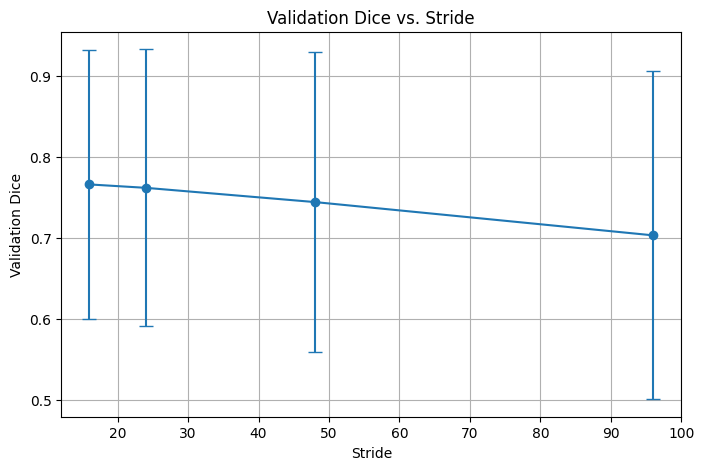

In [47]:
# Dice
plt.figure(figsize=(8, 5))
plt.errorbar(
    stride_summary["stride"],
    stride_summary["validation_dice_mean"],
    yerr=stride_summary["validation_dice_std"],
    marker="o",
    capsize=5,
)
plt.xlabel("Stride")
plt.ylabel("Validation Dice")
plt.title("Validation Dice vs. Stride")
plt.grid(True)
plt.show()

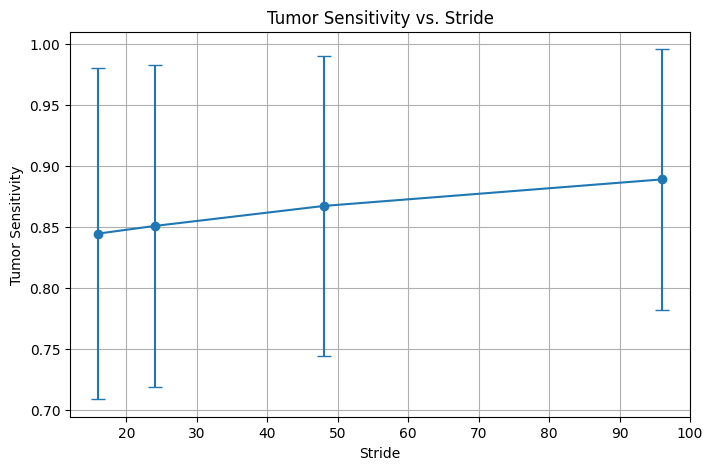

In [48]:
plt.figure(figsize=(8, 5))
plt.errorbar(
    stride_summary["stride"],
    stride_summary["tumor_sensitivity_mean"],
    yerr=stride_summary["tumor_sensitivity_std"],
    marker="o",
    capsize=5,
)
plt.xlabel("Stride")
plt.ylabel("Tumor Sensitivity")
plt.title("Tumor Sensitivity vs. Stride")
plt.grid(True)
plt.show()

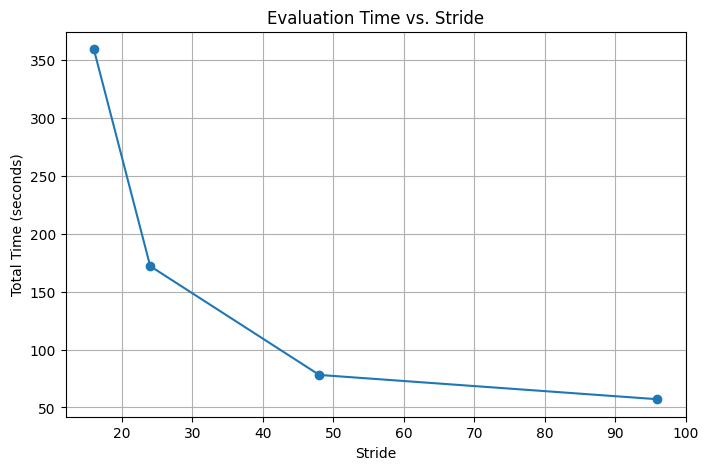

In [50]:
plt.figure(figsize=(8, 5))
plt.plot(
    stride_summary["stride"],
    stride_summary["time_seconds"],
    marker="o",
)
plt.xlabel("Stride")
plt.ylabel("Total Time (seconds)")
plt.title("Evaluation Time vs. Stride")
plt.grid(True)
plt.show()

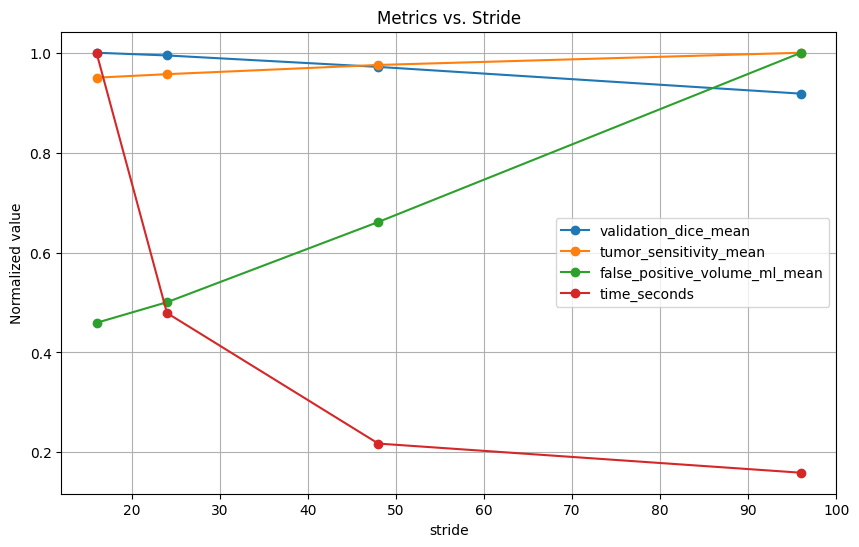

In [45]:
metrics = [
    "validation_dice_mean",
    "tumor_sensitivity_mean",
    "false_positive_volume_ml_mean",
    "time_seconds",
]

plot_df = stride_summary[["stride"] + metrics].copy()

for metric in metrics:
    plot_df[metric] = (
        plot_df[metric] / plot_df[metric].max()
    )

plot_df.plot(
    x="stride",
    marker="o",
    figsize=(10, 6),
)

plt.ylabel("Normalized value")
plt.title("Metrics vs. Stride")
plt.grid(True)
plt.show()

### Eval on Test

In [59]:
test_dataset = BraTSPatchDataset(
    test_df,
    root_dir=DATA_ROOT,
    patch_size=PATCH_SIZE,
    stride=(96, 96, 96),
    train=False,
)

test_evaluation_result = evaluate_validation_model(
    tumor_model, test_dataset, "tumor-aware"
)

tumor-aware: evaluated 73/73 cases


In [61]:
test_eval_summary = summarize_validation_metrics(test_evaluation_result)
test_eval_summary.to_csv("output/test_eval_summary.csv")
test_eval_summary

,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,...,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
condition,,,,,,,,,,,,,,,,,,,,,
tumor-aware,73,0,150.809318,0.762305,0.152297,0.790944,0.637294,0.178804,0.654183,0.89344,...,28.294603,24.46934,21.505,61.527856,161.587103,25.637477,33.737342,24.793611,29.389,-74


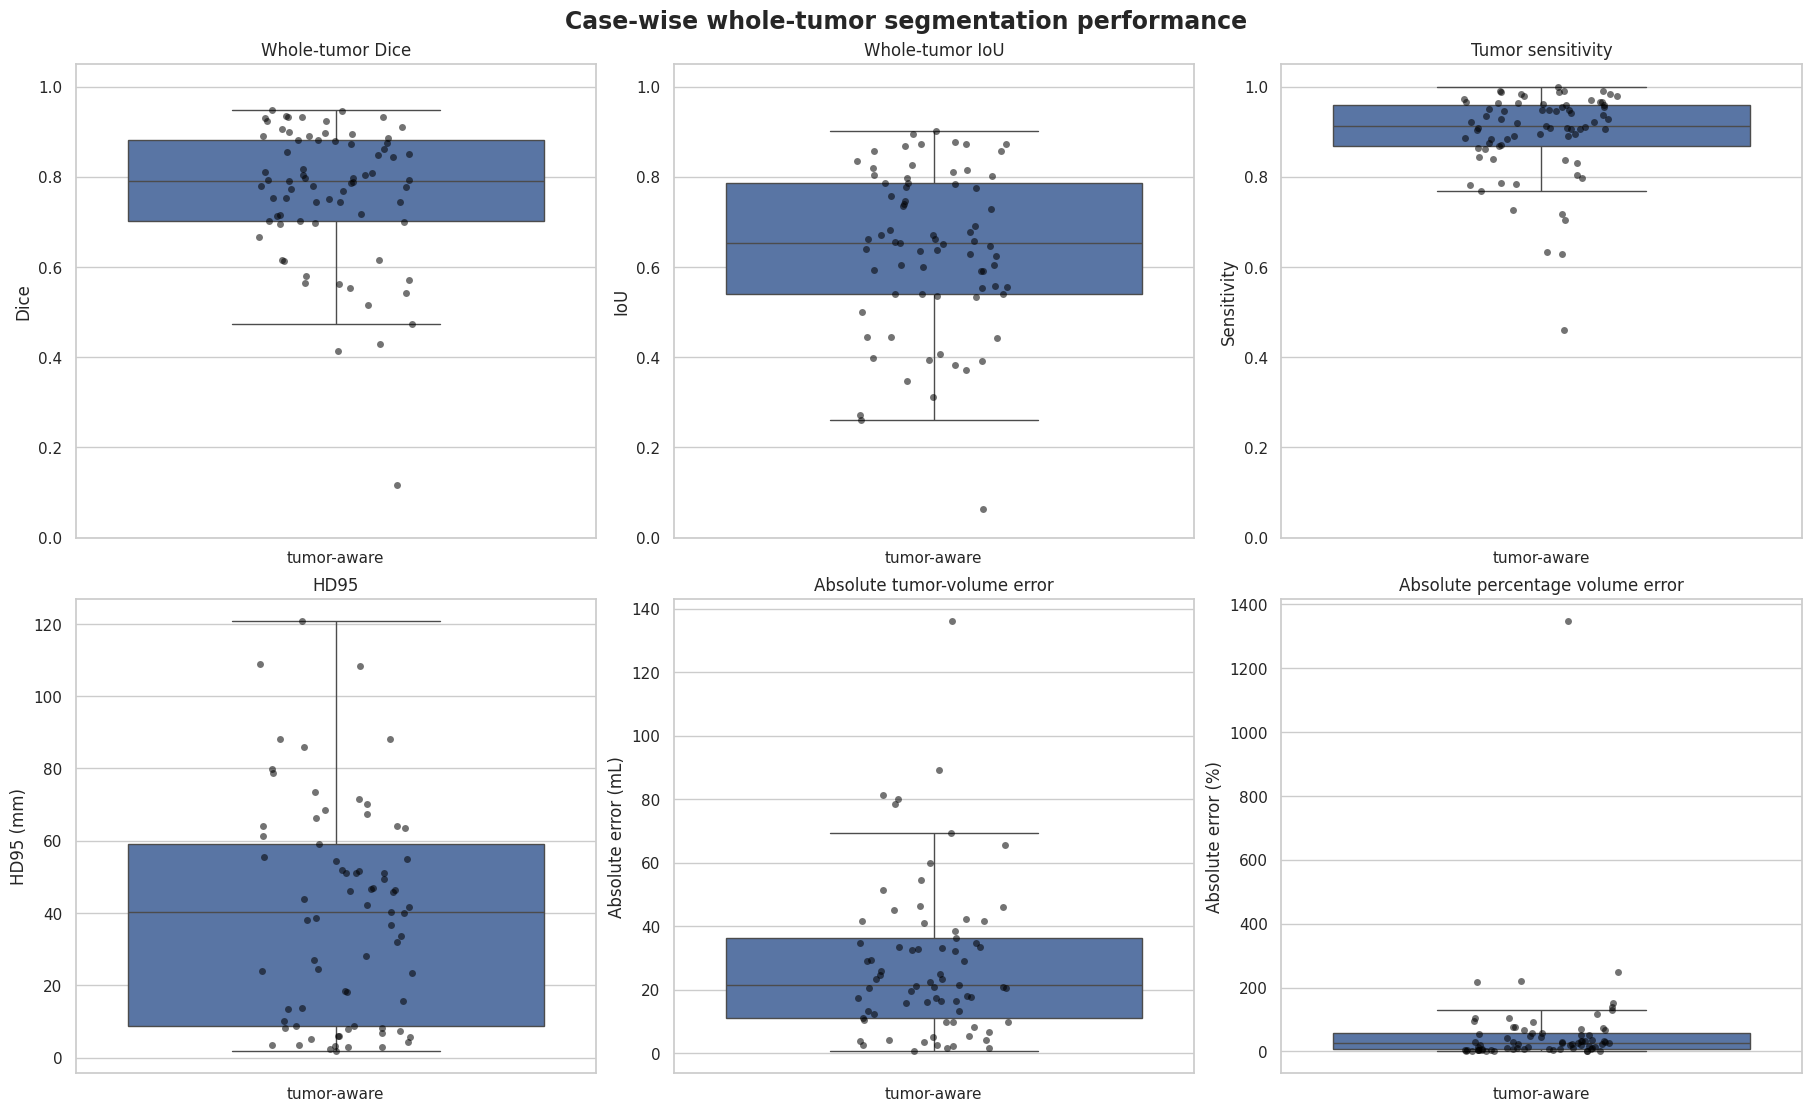

In [65]:
import seaborn as sns


sns.set_theme(style="whitegrid", context="notebook")

def plot_evaluation_results(case_metrics):
    """Plot case-wise segmentation metrics for all evaluated models."""
    data = case_metrics.copy()

    # Infinite HD95 occurs when exactly one mask is empty. It cannot be
    # displayed on a finite axis, so replace it with NaN for plotting only.
    data["hd95_mm_plot"] = data["hd95_mm"].replace(
        [np.inf, -np.inf], np.nan
    )

    model_order = data["model"].drop_duplicates().tolist()

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(18, 11),
        constrained_layout=True,
    )

    # 1. Dice
    sns.boxplot(
        data=data,
        x="model",
        y="whole_tumor_dice",
        order=model_order,
        showfliers=False,
        ax=axes[0, 0],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="whole_tumor_dice",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[0, 0],
    )
    axes[0, 0].set_title("Whole-tumor Dice")
    axes[0, 0].set_xlabel("")
    axes[0, 0].set_ylabel("Dice")
    axes[0, 0].set_ylim(0, 1.05)

    # 2. IoU
    sns.boxplot(
        data=data,
        x="model",
        y="whole_tumor_iou",
        order=model_order,
        showfliers=False,
        ax=axes[0, 1],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="whole_tumor_iou",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[0, 1],
    )
    axes[0, 1].set_title("Whole-tumor IoU")
    axes[0, 1].set_xlabel("")
    axes[0, 1].set_ylabel("IoU")
    axes[0, 1].set_ylim(0, 1.05)

    # 3. Sensitivity
    sns.boxplot(
        data=data,
        x="model",
        y="tumor_sensitivity",
        order=model_order,
        showfliers=False,
        ax=axes[0, 2],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="tumor_sensitivity",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[0, 2],
    )
    axes[0, 2].set_title("Tumor sensitivity")
    axes[0, 2].set_xlabel("")
    axes[0, 2].set_ylabel("Sensitivity")
    axes[0, 2].set_ylim(0, 1.05)

    # 4. HD95
    sns.boxplot(
        data=data,
        x="model",
        y="hd95_mm_plot",
        order=model_order,
        showfliers=False,
        ax=axes[1, 0],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="hd95_mm_plot",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[1, 0],
    )
    axes[1, 0].set_title("HD95")
    axes[1, 0].set_xlabel("")
    axes[1, 0].set_ylabel("HD95 (mm)")

    # 5. Absolute volume error
    sns.boxplot(
        data=data,
        x="model",
        y="absolute_volume_error_ml",
        order=model_order,
        showfliers=False,
        ax=axes[1, 1],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="absolute_volume_error_ml",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[1, 1],
    )
    axes[1, 1].set_title("Absolute tumor-volume error")
    axes[1, 1].set_xlabel("")
    axes[1, 1].set_ylabel("Absolute error (mL)")

    # 6. Percentage volume error
    sns.boxplot(
        data=data,
        x="model",
        y="absolute_volume_error_percentage",
        order=model_order,
        showfliers=False,
        ax=axes[1, 2],
    )
    sns.stripplot(
        data=data,
        x="model",
        y="absolute_volume_error_percentage",
        order=model_order,
        color="black",
        alpha=0.55,
        jitter=0.15,
        ax=axes[1, 2],
    )
    axes[1, 2].set_title("Absolute percentage volume error")
    axes[1, 2].set_xlabel("")
    axes[1, 2].set_ylabel("Absolute error (%)")

    fig.suptitle(
        "Case-wise whole-tumor segmentation performance",
        fontsize=17,
        fontweight="bold",
    )

    plt.show()

plot_evaluation_results(test_evaluation_result)

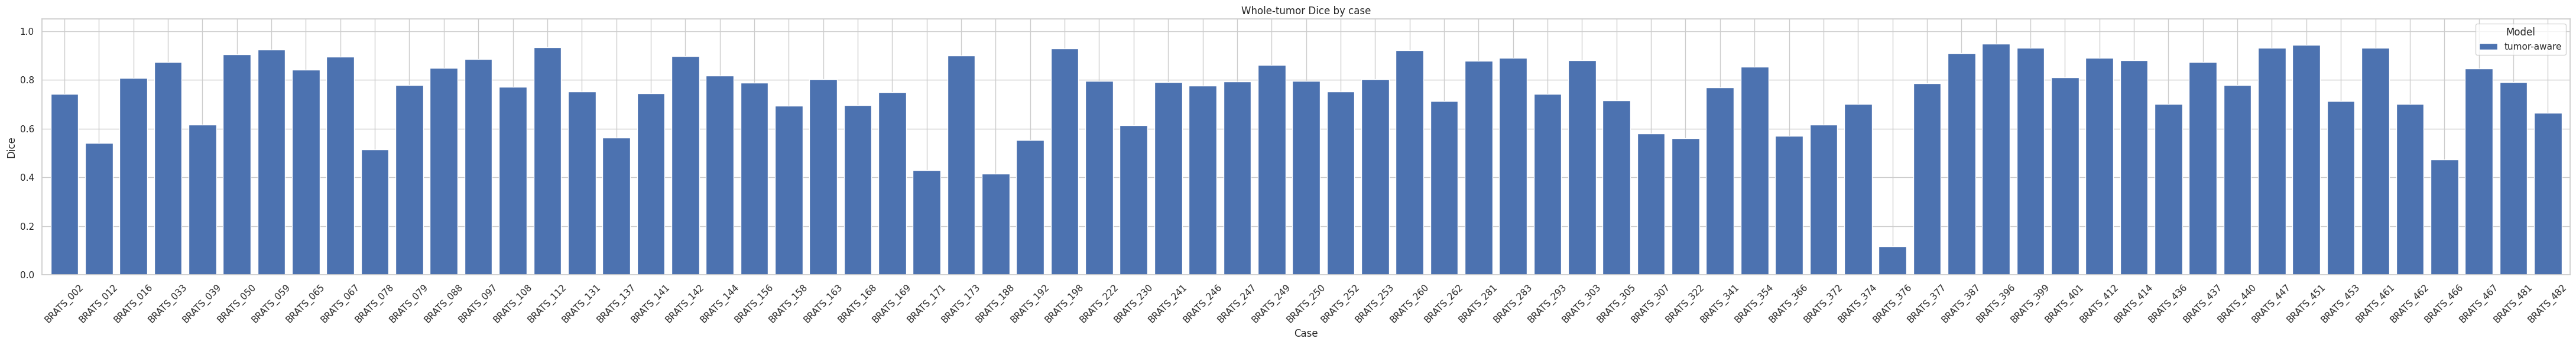

In [66]:
def plot_casewise_dice(case_metrics):
    plot_data = case_metrics.pivot(
        index="case_id",
        columns="model",
        values="whole_tumor_dice",
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(max(12, len(plot_data) * 0.6), 6),
        width=0.8,
    )

    ax.set_title("Whole-tumor Dice by case")
    ax.set_xlabel("Case")
    ax.set_ylabel("Dice")
    ax.set_ylim(0, 1.05)
    ax.legend(title="Model")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()


plot_casewise_dice(test_evaluation_result)

#### Helper

In [68]:
@torch.inference_mode()
def predict_full_case(
    model,
    dataset,
    case_idx,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
):
    """Reconstruct one full-volume prediction using sliding-window averaging."""
    device = torch.device(device)
    model = model.to(device)
    model.eval()

    image, target = dataset._load_case(case_idx)

    # Expected shapes:
    # image:  (C, D, H, W)
    # target: (1, D, H, W)
    _, D, H, W = image.shape
    patch_d, patch_h, patch_w = dataset.patch_size

    d_starts = dataset._get_starts(
        D, patch_d, dataset.stride[0]
    )
    h_starts = dataset._get_starts(
        H, patch_h, dataset.stride[1]
    )
    w_starts = dataset._get_starts(
        W, patch_w, dataset.stride[2]
    )

    locations = [
        (d, h, w)
        for d in d_starts
        for h in h_starts
        for w in w_starts
    ]

    probability_sum = torch.zeros(
        (1, D, H, W), dtype=torch.float32
    )
    prediction_count = torch.zeros_like(probability_sum)

    use_amp = device.type == "cuda"

    for start in range(0, len(locations), batch_size):
        location_batch = locations[start:start + batch_size]

        image_batch = torch.stack([
            dataset._extract_patch(image, target, d, h, w)[0]
            for d, h, w in location_batch
        ]).to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp,
        ):
            logits = model(image_batch)
            probabilities = torch.sigmoid(logits)

        probabilities = probabilities.float().cpu()

        for probability, (d, h, w) in zip(
            probabilities, location_batch
        ):
            probability_sum[
                :,
                d:d + patch_d,
                h:h + patch_h,
                w:w + patch_w,
            ] += probability

            prediction_count[
                :,
                d:d + patch_d,
                h:h + patch_h,
                w:w + patch_w,
            ] += 1

    probability = probability_sum / prediction_count.clamp_min(1)
    prediction = probability >= threshold
    target_binary = target >= 0.5

    return {
        "image": image.cpu(),
        "target": target_binary.cpu(),
        "probability": probability.cpu(),
        "prediction": prediction.cpu(),
    }

In [69]:
def plot_case_prediction(
    result,
    case_id=None,
    slice_idx=None,
    image_channel=0,
):
    """Compare an image slice, ground truth, and predicted tumor mask."""
    image = result["image"][image_channel].numpy()
    target = result["target"][0].numpy().astype(bool)
    prediction = result["prediction"][0].numpy().astype(bool)
    probability = result["probability"][0].numpy()

    if slice_idx is None:
        # Choose the axial slice containing the most ground-truth tumor.
        tumor_per_slice = target.sum(axis=(1, 2))

        if tumor_per_slice.max() > 0:
            slice_idx = int(np.argmax(tumor_per_slice))
        else:
            # If the ground truth is empty, use the slice with the largest
            # predicted tumor region.
            prediction_per_slice = prediction.sum(axis=(1, 2))

            if prediction_per_slice.max() > 0:
                slice_idx = int(np.argmax(prediction_per_slice))
            else:
                slice_idx = image.shape[0] // 2

    image_slice = image[slice_idx]
    target_slice = target[slice_idx]
    prediction_slice = prediction[slice_idx]
    probability_slice = probability[slice_idx]

    # Robust display range so extreme intensities do not dominate.
    finite_values = image_slice[np.isfinite(image_slice)]
    if finite_values.size:
        vmin, vmax = np.percentile(finite_values, [1, 99])
    else:
        vmin, vmax = 0, 1

    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    # Original scan
    axes[0].imshow(
        image_slice,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title("Input scan")

    # Ground-truth mask
    axes[1].imshow(
        target_slice,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1].set_title("Ground truth")

    # Predicted mask
    axes[2].imshow(
        prediction_slice,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[2].set_title("Predicted mask")

    # Probability map
    probability_plot = axes[3].imshow(
        probability_slice,
        cmap="magma",
        vmin=0,
        vmax=1,
    )
    axes[3].set_title("Tumor probability")
    fig.colorbar(
        probability_plot,
        ax=axes[3],
        fraction=0.046,
        pad=0.04,
    )

    # Overlay comparison
    axes[4].imshow(
        image_slice,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )

    # Green = ground truth, red = prediction.
    axes[4].imshow(
        np.ma.masked_where(~target_slice, target_slice),
        cmap="Greens",
        alpha=0.45,
        vmin=0,
        vmax=1,
    )
    axes[4].imshow(
        np.ma.masked_where(~prediction_slice, prediction_slice),
        cmap="Reds",
        alpha=0.45,
        vmin=0,
        vmax=1,
    )
    axes[4].set_title("Overlay: GT green, prediction red")

    for axis in axes:
        axis.axis("off")

    title = f"Case {case_id} — axial slice {slice_idx}"
    fig.suptitle(title, fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

#### Continue

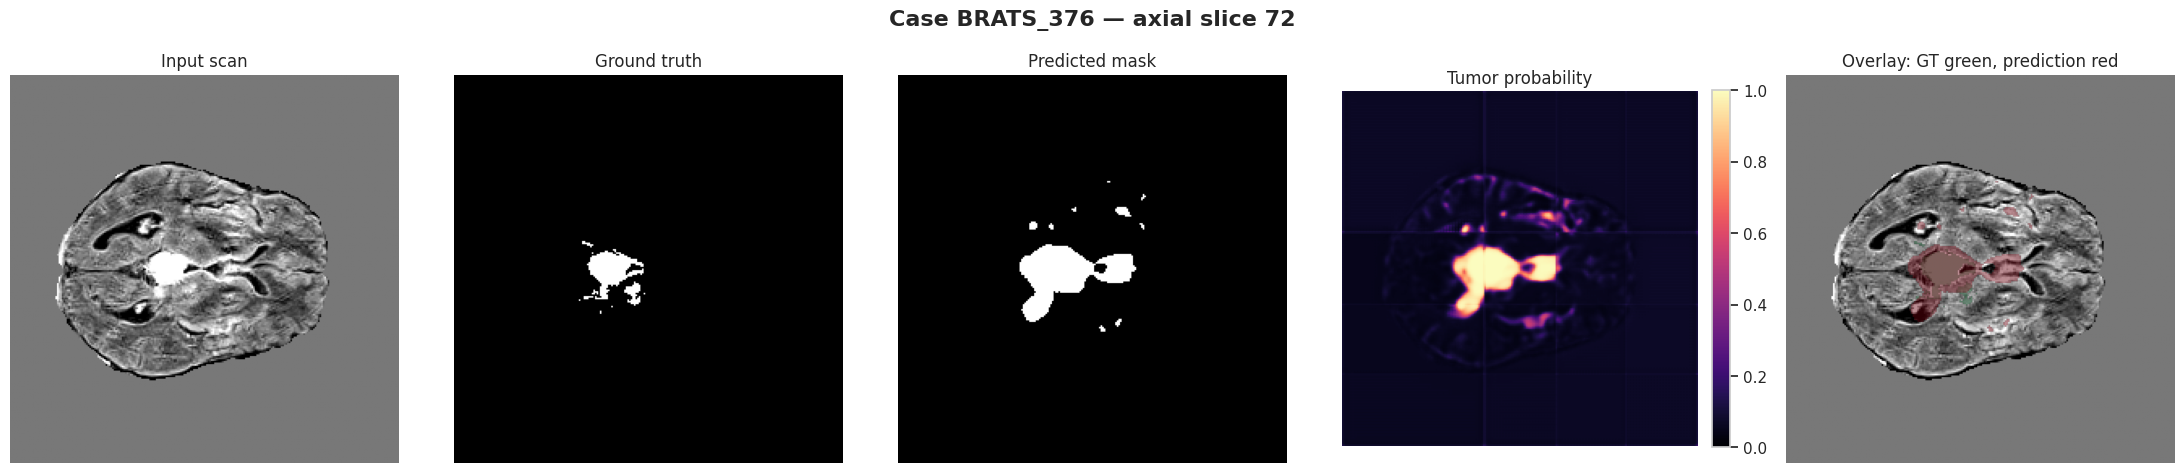

In [75]:
case_idx = 53
case_id = test_dataset.df.iloc[case_idx]["case_id"]

result = predict_full_case(
    model=tumor_model,
    dataset=test_dataset,
    case_idx=case_idx,
    threshold=0.5,
    batch_size=2,
    device=DEVICE,
)

plot_case_prediction(
    result,
    case_id=case_id,
)

## Postprocessing

In [78]:
from scipy.ndimage import label, generate_binary_structure

def connected_component_postprocessing(
    mask,
    keep_n_components=1,
    min_component_voxels=0,
    connectivity=3,
):
    """Apply 3D connected-component filtering to a binary prediction.

    Parameters
    ----------
    mask : np.ndarray, shape (D, H, W)
        Binary predicted mask.

    keep_n_components : int or None
        Number of largest valid components to retain.
        Use 1 to retain only the largest connected component.
        Use None to retain every component passing the minimum-size rule.

    min_component_voxels : int
        Remove components containing fewer than this number of voxels.
        Set to 0 to disable minimum-size filtering.

    connectivity : {1, 2, 3}
        3D connectivity:
        1 = 6-connected
        2 = 18-connected
        3 = 26-connected

    Returns
    -------
    np.ndarray
        Postprocessed Boolean mask with shape (D, H, W).
    """
    mask = np.asarray(mask, dtype=bool)

    if mask.ndim != 3:
        raise ValueError(
            f"Expected a 3D mask with shape (D, H, W), got {mask.shape}"
        )

    if not mask.any():
        return mask.copy()

    if connectivity not in (1, 2, 3):
        raise ValueError("connectivity must be 1, 2, or 3")

    if keep_n_components is not None and keep_n_components < 1:
        raise ValueError("keep_n_components must be at least 1 or None")

    structure = generate_binary_structure(
        rank=3,
        connectivity=connectivity,
    )

    component_labels, number_of_components = label(
        mask,
        structure=structure,
    )

    if number_of_components == 0:
        return np.zeros_like(mask, dtype=bool)

    # Index 0 is the background and is ignored.
    component_sizes = np.bincount(component_labels.ravel())
    component_ids = np.arange(1, number_of_components + 1)
    foreground_sizes = component_sizes[1:]

    # Remove components below the minimum size.
    valid = foreground_sizes >= min_component_voxels
    valid_component_ids = component_ids[valid]
    valid_component_sizes = foreground_sizes[valid]

    if valid_component_ids.size == 0:
        return np.zeros_like(mask, dtype=bool)

    # Sort valid components from largest to smallest.
    descending_order = np.argsort(valid_component_sizes)[::-1]
    valid_component_ids = valid_component_ids[descending_order]

    if keep_n_components is not None:
        valid_component_ids = valid_component_ids[:keep_n_components]

    return np.isin(component_labels, valid_component_ids)

In [79]:
tumor_metrics_lcc = evaluate_validation_model(
    tumor_model,
    val_dataset,
    model_name="tumor-aware LCC",
    postprocess_fn=connected_component_postprocessing,
    postprocess_kwargs={
        "keep_n_components": 1,
        "min_component_voxels": 0,
        "connectivity": 3,
    },
)

summarize_validation_metrics(tumor_metrics_lcc)

tumor-aware LCC: evaluated 73/73 cases


,cases,empty_predictions,time_seconds,whole_tumor_dice_mean,whole_tumor_dice_std,whole_tumor_dice_median,whole_tumor_iou_mean,whole_tumor_iou_std,whole_tumor_iou_median,tumor_sensitivity_mean,...,absolute_volume_error_ml_mean,absolute_volume_error_ml_std,absolute_volume_error_ml_median,absolute_volume_error_percentage_mean,absolute_volume_error_percentage_std,absolute_volume_error_percentage_median,false_positive_volume_ml_mean,false_positive_volume_ml_std,false_positive_volume_ml_median,nonfinite_hd95_cases
condition,,,,,,,,,,,,,,,,,,,,,
tumor-aware LCC,73,0,173.653121,0.78465,0.203581,0.856814,0.6799,0.211465,0.749497,0.823568,...,21.170808,24.038985,13.99,42.802146,101.345536,17.332406,18.38526,22.43875,12.394,-74
